# Лабораторная работа № 5. Адаптация модели машинного перевода

**Направление:** Цифровая лингвистика и локализация.

## Цель
Проверить, как дообучение готовой англо-русской модели на переводах проекта меняет
качество перевода новых строк. Сравнить результат с исходной моделью и с поиском
по памяти переводов.

**Адаптация (дообучение)** — продолжение обучения готовой модели на небольшом наборе
своих текстов, чтобы она лучше передавала их термины и стиль.

Работа опирается на работы № 1–3; работа № 4 для неё не нужна.

| Из работы | Что применяем здесь |
|---|---|
| № 1: обучение и проверка | обучающая, проверочная и тестовая части; контроль переобучения |
| № 2: память переводов | поиск ближайшего сегмента (символьный TF-IDF и косинус) как базовое решение |
| № 3: оценка качества | BLEU, chrF, технические проверки и ручной разбор ошибок |

**Исследовательский вопрос:** улучшает ли адаптация перевод новых строк или в основном
помогает повторять знакомые формулировки?

В учебном корпусе всего 160 пар. Для небольшого опыта этого хватает, но устойчивого
улучшения заранее обещать нельзя. Оценивается, правильно ли поставлен опыт и как
объяснён результат, даже если улучшения нет.

### Словарь работы

| Термин | Что значит |
|---|---|
| токен | слово или часть слова, с которой работает модель |
| эпоха | один полный проход по обучающей части |
| потеря (loss) | число, показывающее, насколько модель ошибается на эталоне; чем меньше, тем лучше |
| пакет (batch) | несколько примеров, которые модель обрабатывает за один шаг |
| заполнитель (padding) | служебный токен, выравнивающий длину строк в пакете |
| кодировщик и декодировщик | две части модели: первая читает оригинал, вторая пишет перевод |
| лучевой поиск (beam search) | способ генерации: модель держит несколько вариантов продолжения и выбирает лучший |
| seed (зерно) | начальное число генератора случайных чисел; с ним опыт можно повторить |
| переобучение | модель запоминает обучающие примеры, а на новых работает хуже |

## 1. Подготовка и режим запуска

Откройте ноутбук из папки, в которой лежит папка `data/`. Ноутбук использует корпус
`data/loc_corpus.csv` и пример готового запуска `data/lab5_demo/`.

Режим задаётся переменной `MODE` в следующем блоке:

* **`MODE = "train"`** — настоящий опыт: скачать модель, получить её переводы до обучения,
  дообучить, выбрать лучшую эпоху по проверочной части и один раз оценить её на тестовой.
  Желательна видеокарта (GPU); на обычном процессоре (CPU) работа займёт заметно больше времени.
* **`MODE = "saved"`** — разобрать сохранённый запуск без PyTorch, видеокарты и интернета.
  Разбиение, поиск, метрики и проверки выполняются заново, а переводы нейросети читаются
  из файлов. Новое обучение в этом режиме не выполняется.

Для режима `train` создайте отдельное окружение Python 3.12 и установите зависимости
из файла `requirements-translation.txt`. В комплекте он лежит рядом с ноутбуком,
в репозитории курса — на уровень выше (`../requirements-translation.txt`):

```sh
python -m pip install -r requirements-translation.txt
```

Для видеокарты установите подходящую сборку PyTorch по инструкции https://pytorch.org/get-started/locally/.
В Colab выполните следующую команду **до импортов**, затем при необходимости перезапустите ядро:

```python
%pip install "transformers==4.57.1" "sentencepiece==0.2.2" "sacremoses==0.2.0" "sacrebleu==2.6.0" "scikit-learn>=1.5,<1.8" pandas matplotlib
```

Загрузите в Colab папку `data/` из комплекта. Модель загружать не нужно: ноутбук скачает её сам.
Для режима `saved` достаточно зависимостей работ № 1–3 (включая sacrebleu).

**Что делает следующий блок:** выбирает режим, подключает библиотеки и задаёт параметры опыта.

In [4]:
import os
from pathlib import Path

# Измените MODE вручную. Переменная окружения нужна для автоматического прогона.
MODE = os.environ.get("MLG_LAB5_MODE", "train")  # "train" или "saved"
assert MODE in {"train", "saved"}

# На Windows torch нужно импортировать раньше numpy, pandas и sklearn.
if MODE == "train":
    os.environ.setdefault("USE_TF", "0")  # здесь используется только PyTorch
    import torch

import copy
import hashlib
import importlib.metadata
import json
import re
import time
import unicodedata
from collections import Counter
from datetime import datetime, timezone
from difflib import SequenceMatcher

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sacrebleu.metrics import BLEU, CHRF

SEED = 42
NEAR_DUPLICATE_THRESHOLD = 0.88
MODEL_NAME = "Helsinki-NLP/opus-mt-en-ru"
# Фиксируем версию модели, а не изменяемую ветку main.
MODEL_REVISION = "bb09c99d180016eac6819df3dae68edb1690fdee"
EPOCHS = 5
LEARNING_RATE = 2e-5
BATCH_SIZE = 8
MAX_TOKENS = 128
NUM_BEAMS = 4
EXPORT_MODEL = False  # веса сохраняются только по явному выбору

DATA = Path("data")
CORPUS_PATH = DATA / "loc_corpus.csv"
DEMO_DIR = DATA / "lab5_demo"
print("Режим:", MODE)

Режим: train


## 2. Данные

Модель учится на парах «английский оригинал `en` → эталонный русский перевод `ru_ref`».
Столбец `ru_mt` из третьей работы здесь не нужен: исходную модель запускаем заново
с теми же настройками генерации, что и адаптированную.

Поле `id` связывает строку с её переводами на всех этапах. Поле `type` (тип контента)
нужно, чтобы проверить состав частей и сравнить результаты по типам. Модели оно
не передаётся.

**Что делает следующий блок:** загружает корпус, проверяет, что в нём нет пустых полей
и повторных `id`, и показывает число сегментов каждого типа.

In [5]:
def load_corpus(path):
    data = pd.read_csv(path, dtype=str, keep_default_na=False)
    required = {"id", "type", "en", "ru_ref"}
    if not required.issubset(data.columns):
        raise ValueError(f"Не хватает столбцов: {required - set(data.columns)}")
    if data["id"].duplicated().any():
        raise ValueError("Идентификаторы сегментов должны быть уникальны.")
    if data[list(required)].apply(lambda column: column.str.strip().eq("")).any().any():
        raise ValueError("В обязательных полях есть пустые значения.")
    return data.sort_values("id").reset_index(drop=True)


def corpus_fingerprint(data):
    # Отпечаток не зависит от порядка строк и вида переносов строк в CSV.
    rows = data.sort_values("id")[["id", "type", "en", "ru_ref"]].to_dict("records")
    return hashlib.sha256(json.dumps(rows, ensure_ascii=False, sort_keys=True).encode("utf-8")).hexdigest()


corpus = load_corpus(CORPUS_PATH)
DATA_SHA256 = corpus_fingerprint(corpus)
display(corpus.groupby("type").size().rename("Сегментов").to_frame())
display(corpus[["id", "type", "en", "ru_ref"]].head())

,Сегментов
type,
документация,40
интерфейс,40
маркетинг,40
юридический,40


,id,type,en,ru_ref
0,s001,интерфейс,Save changes,Сохранить изменения
1,s002,интерфейс,"Delete file ""{name}""?",Удалить файл «{name}»?
2,s003,интерфейс,Sign in with your work account,Войдите с рабочей учётной записью
3,s004,интерфейс,Your session has expired,Срок действия сеанса истёк
4,s005,интерфейс,Loading…,Загрузка…


## 3. Группы похожих строк и разбиение корпуса

Если разбить корпус на части случайно, варианты одного шаблона могут попасть и в обучение,
и в тест. Тогда модель «узнает» тестовую строку, и качество окажется завышенным.
Поэтому сначала объединяем похожие **оригиналы** в группы.

Перед сравнением строки упрощаются: регистр выравнивается, а поля вроде `{name}` и числа
заменяются условными словами. Сходство считается по символам. Строки со сходством
не ниже 0,88 попадают в одну группу. Если A похоже на B, а B — на C, все три строки
окажутся в одной группе. Модель и метрики получают исходный текст, а не упрощённый.

Это приблизительный способ: он не найдёт строки, похожие только по смыслу. Просмотрите
найденные группы и при необходимости дополните их **до** обучения.

Затем корпус делится примерно так: 60 % — обучающая часть, 20 % — проверочная,
20 % — тестовая. Группа целиком попадает в одну часть, а типы контента распределяются
поровну. Если строк с числами и полями достаточно, разбиение подбирается так, чтобы они
были в каждой части. При подборе используются только оригиналы и типы, но не переводы.
Выбранный seed сохраняется в описании запуска.

**Что делает следующий блок:** находит группы, делит корпус и показывает состав частей.

In [6]:
def normalize_for_group(text):
    text = unicodedata.normalize("NFKC", str(text)).casefold()
    text = re.sub(r"\{[^}]*\}|%[sd]", " field ", text)
    text = re.sub(r"\d+(?:[.,]\d+)?", " number ", text)
    return " ".join(re.findall(r"\w+", text))


def duplicate_groups(data, threshold=0.88):
    if not 0 < threshold <= 1:
        raise ValueError("Порог должен быть в интервале (0, 1].")
    normalized = [normalize_for_group(text) for text in data["en"]]
    parent = list(range(len(data)))

    def root(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i

    for i, a in enumerate(normalized):
        for j in range(i):
            b = normalized[j]
            # Сходство считаем в обе стороны: результат может зависеть от порядка строк.
            score = max(SequenceMatcher(None, a, b, autojunk=False).ratio(),
                        SequenceMatcher(None, b, a, autojunk=False).ratio())
            if score >= threshold:
                parent[root(i)] = root(j)
    members = {}
    for i in range(len(data)):
        members.setdefault(root(i), []).append(str(data.iloc[i]["id"]))
    names = {key: min(ids) for key, ids in members.items()}
    return pd.Series([names[root(i)] for i in range(len(data))], index=data.index, name="group")


def split_corpus(data, seed=42, threshold=0.88):
    result = data.copy().reset_index(drop=True)
    result["group"] = duplicate_groups(result, threshold)
    source_flags = {
        "fields": result["en"].str.contains(r"\{[^}]*\}|%[sd]|<[^>]+>", regex=True),
        "numbers": result["en"].str.contains(r"\d", regex=True),
    }
    # Требуем присутствие признака во всех частях, если он встречается
    # хотя бы в трёх разных группах. Эталоны и метрики здесь не читаются.
    required_flags = [mask for mask in source_flags.values()
                      if result.loc[mask, "group"].nunique() >= 3]
    expected_types = set(result["type"])
    for split_seed in range(seed, seed + 200):
        splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=split_seed)
        fold = np.full(len(result), -1, dtype=int)
        for k, (_, indices) in enumerate(splitter.split(result["en"], result["type"], result["group"])):
            fold[indices] = k
        assert (fold >= 0).all()
        names = np.where(fold == 4, "test", np.where(fold == 3, "validation", "train"))
        parts = [names == name for name in ["train", "validation", "test"]]
        balanced = all(set(result.loc[part, "type"]) == expected_types for part in parts)
        covered = all(mask[part].any() for mask in required_flags for part in parts)
        if balanced and covered:
            result["split"] = names
            result.attrs["split_seed"] = split_seed
            if result.groupby("group")["split"].nunique().max() != 1:
                raise AssertionError("Одна группа попала в разные части.")
            return result
    raise ValueError("Не удалось сохранить группы, типы и технические примеры: проверьте состав корпуса.")


split_data = split_corpus(corpus, SEED, NEAR_DUPLICATE_THRESHOLD)
train = split_data.query("split == 'train'").copy().reset_index(drop=True)
validation = split_data.query("split == 'validation'").copy().reset_index(drop=True)
test = split_data.query("split == 'test'").copy().reset_index(drop=True)
display(pd.crosstab(split_data["type"], split_data["split"]))
grouped_rows = split_data.loc[split_data["group"].duplicated(keep=False), ["id", "group", "split", "en"]]
display(grouped_rows)
print("Групп:", split_data["group"].nunique(), "из", len(split_data), "сегментов.")
if grouped_rows.empty:
    print("При выбранном пороге близких пар не найдено: все группы состоят из одной строки.")
print("Зерно выбранного разбиения:", split_data.attrs["split_seed"])
coverage = split_data.assign(поля=split_data.en.str.contains(r"\{[^}]*\}|%[sd]|<[^>]+>", regex=True), числа=split_data.en.str.contains(r"\d", regex=True))
display(coverage.groupby("split")[["поля", "числа"]].sum())

split,test,train,validation
type,,,
документация,8,24,8
интерфейс,8,24,8
маркетинг,8,24,8
юридический,8,24,8


,id,group,split,en


Групп: 160 из 160 сегментов.
При выбранном пороге близких пар не найдено: все группы состоят из одной строки.
Зерно выбранного разбиения: 81


,поля,числа
split,,
test,1,3
train,1,6
validation,1,1


**Роли частей.** На обучающей части (`train`) модель меняет свои веса. По проверочной
(`validation`) выбираем эпоху и настройки. Тестовая (`test`) нужна только для итогового
сравнения. Если менять настройки после просмотра теста, он превращается во вторую
проверочную часть, и для честного вывода понадобится новый тест.
Мы не знаем, встречались ли похожие строки в данных, на которых модель обучали изначально.

## 4. Базовое решение: память переводов

В память попадает только обучающая часть. Для каждого нового оригинала ищем самый
похожий английский оригинал в памяти (по косинусу символьных TF-IDF-векторов, как
в работе № 2) и возвращаем его русский перевод.

Это поиск, а не перевод: числа, поля и словоформы в найденной строке не исправляются.
Если у новой строки нет ни одного общего буквосочетания с памятью, подсказки не будет.
Косинус показывает сходство оригиналов, а не вероятность того, что перевод верен.

**Что делает следующий блок:** строит память из обучающей части и находит подсказку
для каждой тестовой строки.

In [7]:
def translation_memory(memory, queries):
    vectorizer = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4))
    matrix = vectorizer.fit_transform(memory["en"])
    query_vectors = vectorizer.transform(queries["en"])
    similarities = cosine_similarity(query_vectors, matrix)
    rows = []
    for i, (_, query) in enumerate(queries.iterrows()):
        best = int(similarities[i].argmax())
        score = float(similarities[i, best])
        rows.append({"id": query["id"], "system": "tm", "prediction": memory.iloc[best]["ru_ref"] if score > 0 else "",
                     "tm_id": memory.iloc[best]["id"] if score > 0 else "", "tm_cosine": score})
    return pd.DataFrame(rows)


tm_predictions = translation_memory(train, test)
assert set(tm_predictions["tm_id"]) - {""} <= set(train["id"])
display(test[["id", "en"]].merge(tm_predictions, on="id", validate="one_to_one").head(8))

,id,en,system,prediction,tm_id,tm_cosine
0,s005,Loading…,tm,Перетащите файлы сюда для загрузки,s032,0.271603
1,s010,Unable to connect to the server,tm,Параметр задаёт максимальное число одновременн...,s043,0.251763
2,s017,Upload a profile photo,tm,Перетащите файлы сюда для загрузки,s032,0.473927
3,s020,Storage almost full,tm,"Файлы журналов хранятся 30 дней, после чего уд...",s047,0.166722
4,s024,Notifications are turned off,tm,Превращайте отзывы в решения.,s109,0.221408
5,s028,Session will end in {minutes} min,tm,"Настройка занимает минуты, а не недели.",s086,0.384764
6,s034,Your changes were saved,tm,Сохранить изменения,s001,0.729580
7,s038,Connection restored,tm,Параметр задаёт максимальное число одновременн...,s043,0.291667


## 5. Какую модель дообучаем

Берём `Helsinki-NLP/opus-mt-en-ru` — готовую модель перевода с английского на русский.
Она состоит из кодировщика, который читает оригинал, и декодировщика, который пишет перевод
токен за токеном. Токенизатор (правила разбиения текста на токены) при адаптации не меняется.

При обучении декодировщик видит правильные предыдущие токены эталона и угадывает
следующий. Такой приём называют teacher forcing, «обучение с подсказкой». При переводе
подсказки нет: предыдущие токены модель выбирает сама и может накапливать ошибки.
Поэтому низкая потеря при обучении ещё не значит, что модель хорошо переводит сама.

Условия сравнения задаём заранее: одна и та же исходная модель, один тестовый набор
и одинаковые настройки генерации для исходной и адаптированной систем.

**Что делает следующий блок:** собирает параметры опыта. В режиме `saved` он читает
сохранённый запуск, в режиме `train` скачивает модель.

In [8]:
GENERATION = {"num_beams": NUM_BEAMS, "do_sample": False, "max_new_tokens": MAX_TOKENS}
EXPERIMENT = {
    "model": MODEL_NAME, "revision": MODEL_REVISION,
    "split_policy": "source_coverage_v1",
    "seed": SEED, "near_duplicate_threshold": NEAR_DUPLICATE_THRESHOLD,
    "epochs": EPOCHS, "learning_rate": LEARNING_RATE, "batch_size": BATCH_SIZE,
    "max_tokens": MAX_TOKENS, "generation": GENERATION,
}

def load_saved_run(directory, current_data, current_split, experiment):
    manifest = json.loads((directory / "manifest.json").read_text(encoding="utf-8"))
    if manifest["corpus_sha256"] != corpus_fingerprint(current_data):
        raise ValueError("Сохранённый запуск относится к другому корпусу. Выберите train или исходный корпус.")
    if manifest["experiment"] != experiment:
        raise ValueError("Параметры отличаются от сохранённого опыта. Режим saved не пересчитывает обучение.")
    stored_split = pd.read_csv(directory / "split.csv", dtype=str, keep_default_na=False)
    keys = ["id", "group", "split"]
    if not stored_split[keys].sort_values("id").reset_index(drop=True).equals(
            current_split[keys].sort_values("id").reset_index(drop=True)):
        raise ValueError("Разбиение не совпадает с сохранённым: проверьте версию sklearn и параметры.")
    predictions = pd.read_csv(directory / "predictions.csv", dtype=str, keep_default_na=False)
    return manifest, predictions, pd.read_csv(directory / "history.csv")


if MODE == "saved":
    run_manifest, neural_predictions, history = load_saved_run(DEMO_DIR, corpus, split_data, EXPERIMENT)
    best_epoch = run_manifest["best_epoch"]
    print("Читаем сохранённый запуск:", run_manifest["created_utc"])
    print("Оборудование этого запуска:", run_manifest["device"])
else:
    from torch.utils.data import DataLoader
    from transformers import AutoTokenizer, AutoModelForSeq2SeqLM, DataCollatorForSeq2Seq, set_seed

    set_seed(SEED)
    torch.set_num_threads(min(4, os.cpu_count() or 1))
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    device_name = torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU"
    print("Устройство:", device_name)
    if device.type == "cpu":
        print("Вычисления на CPU могут быть длительными. Для разбора готового опыта доступен MODE='saved'.")
    tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, revision=MODEL_REVISION)
    model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME, revision=MODEL_REVISION).to(device)
    model.config.use_cache = False
    print("Параметров модели:", f"{sum(p.numel() for p in model.parameters()):,}")

Устройство: NVIDIA GeForce RTX 5080
Параметров модели: 76,672,000


## 6. Подготовка примеров для обучения

Оригиналы и эталоны разбиваются на токены. Примеры объединяются в пакеты по
`BATCH_SIZE` штук, а короткие строки дополняются заполнителями до общей длины.
В эталоне заполнителям присваивается значение `-100`, чтобы они не влияли на потерю.
Остальную подготовку входа декодировщика библиотека выполняет сама.

Длинные предложения не обрезаются молча. Если текст длиннее `MAX_TOKENS` токенов,
код остановится и попросит увеличить предел. Такое изменение нужно указать в отчёте.

**Что делает следующий блок:** готовит примеры и показывает размеры одного пакета.

In [9]:
if MODE == "train":
    def encode_pairs(frame):
        encoded = tokenizer(frame["en"].tolist(), text_target=frame["ru_ref"].tolist(), truncation=False)
        if any(len(ids) > MAX_TOKENS for ids in encoded["input_ids"] + encoded["labels"]):
            raise ValueError("Есть слишком длинный сегмент: увеличьте MAX_TOKENS вместо скрытого обрезания.")
        return [{key: values[i] for key, values in encoded.items()} for i in range(len(frame))]

    collator = DataCollatorForSeq2Seq(tokenizer=tokenizer, model=model, label_pad_token_id=-100)
    # Копии нужны, чтобы дополнение пакета не меняло сохранённые примеры.
    def collate(features):
        return collator(copy.deepcopy(features))

    train_examples = encode_pairs(train)
    validation_examples = encode_pairs(validation)
    generator = torch.Generator().manual_seed(SEED)
    train_loader = DataLoader(train_examples, batch_size=BATCH_SIZE, shuffle=True,
                              generator=generator, collate_fn=collate, num_workers=0)
    train_eval_loader = DataLoader(train_examples, batch_size=BATCH_SIZE, collate_fn=collate)
    validation_loader = DataLoader(validation_examples, batch_size=BATCH_SIZE, collate_fn=collate)
    example_batch = next(iter(train_eval_loader))
    print("Размеры тензоров:", {name: tuple(value.shape) for name, value in example_batch.items()})
    print("Позиции, исключённые из потерь:", int((example_batch["labels"] == -100).sum()))

Размеры тензоров: {'input_ids': (8, 9), 'attention_mask': (8, 9), 'labels': (8, 10), 'decoder_input_ids': (8, 10)}
Позиции, исключённые из потерь: 31


## 7. Переводы исходной модели

Переведём тестовые оригиналы до того, как модель изменится. Обе нейросетевые системы
используют лучевой поиск с одинаковыми параметрами. Эталоны теста пока не смотрим,
и эти переводы не используем для выбора настроек.

Если перевод упёрся в предел длины, это отмечается отдельно: обрезанный перевод
нельзя незаметно принять за обычный.

**Что делает следующий блок:** получает переводы тестовых строк исходной моделью.

In [10]:
if MODE == "train":
    def translate(frame, system):
        model.eval()
        rows = []
        for start in range(0, len(frame), BATCH_SIZE):
            part = frame.iloc[start:start + BATCH_SIZE]
            inputs = tokenizer(part["en"].tolist(), padding=True, truncation=False, return_tensors="pt")
            if inputs["input_ids"].shape[1] > MAX_TOKENS:
                raise ValueError("Оригинал длиннее MAX_TOKENS: генерация не должна молча обрезать вход.")
            inputs = {name: tensor.to(device) for name, tensor in inputs.items()}
            with torch.inference_mode():
                sequences = model.generate(**inputs, **GENERATION, use_cache=True)
            texts = tokenizer.batch_decode(sequences, skip_special_tokens=True)
            for segment_id, tokens, prediction in zip(part["id"], sequences.tolist(), texts):
                # Первый токен служебный. Проверяем, закончила ли модель перевод сама
                # или упёрлась в предел длины.
                generated = tokens[1:]
                eos_positions = [i for i, value in enumerate(generated) if value == tokenizer.eos_token_id]
                hit_limit = not eos_positions or eos_positions[0] >= MAX_TOKENS - 1
                rows.append({"id": segment_id, "system": system, "prediction": prediction,
                             "hit_length_limit": bool(hit_limit)})
        return pd.DataFrame(rows)

    base_predictions = translate(test, "base")
    print("Исходные переводы сохранены в памяти. Итоговое сравнение — после выбора эпохи.")

Исходные переводы сохранены в памяти. Итоговое сравнение — после выбора эпохи.


## 8. Дообучение и выбор эпохи

Модель учится уменьшать потерю — среднюю ошибку в предсказании правильных токенов перевода:

$$
L=-\frac{1}{M}\sum_{i,t}\log P_\theta(y_{i,t}\mid x_i,y_{i,<t}),
$$

где $M$ — число токенов эталона без заполнителей. Чем выше вероятность, которую модель
даёт правильному токену, тем меньше потеря. Остальные настройки обучения (оптимизатор
AdamW, ограничение размера шага) стандартные, менять их не требуется.

После каждой эпохи измеряем потерю на обучающей и на проверочной части одинаковым
способом, поэтому две кривые можно сравнивать. Тест в этом цикле не участвует.

Обучающая потеря обычно падает всё время. Если проверочная перестала падать или растёт,
модель начинает переобучаться. Выбираем эпоху с наименьшей проверочной потерей.

**Эпоха 0 — это исходная модель.** Если дообучение не уменьшило проверочную потерю,
останется исходная модель. Это допустимый результат; его нужно прямо указать в отчёте.
Наименьшая проверочная потеря не гарантирует наибольший BLEU.

**Что делает следующий блок:** дообучает модель, выбирает лучшую эпоху, переводит тест
и строит график двух кривых.

Эпоха 0: {'epoch': 0, 'train_loss': 1.1051615632098655, 'validation_loss': 1.1095345643682217, 'seconds': 0.0}
Эпоха 1: train=0.7571, validation=1.0032
Эпоха 2: train=0.4943, validation=0.9542
Эпоха 3: train=0.3255, validation=0.9378
Эпоха 4: train=0.2081, validation=0.9220
Эпоха 5: train=0.1291, validation=0.9172
Выбрана эпоха: 5 (0 означает исходные веса)


,epoch,train_loss,validation_loss,seconds
0,0,1.105162,1.109535,0.000000
1,1,0.757093,1.003168,0.930318
2,2,0.494312,0.954238,1.615724
3,3,0.325462,0.937766,2.255569
4,4,0.208112,0.922044,2.887191
5,5,0.129122,0.917226,3.521154


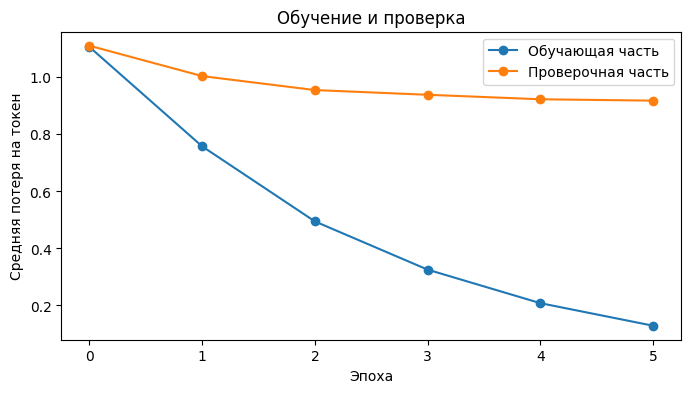

In [11]:
if MODE == "train":
    def token_loss(loader):
        model.eval()
        weighted_loss, token_count = 0.0, 0
        with torch.inference_mode():
            for batch in loader:
                batch = {name: value.to(device) for name, value in batch.items()}
                count = int((batch["labels"] != -100).sum())
                loss = model(**batch).loss
                weighted_loss += float(loss) * count
                token_count += count
        return weighted_loss / token_count

    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=0.01)
    started = time.perf_counter()
    records = [{"epoch": 0, "train_loss": token_loss(train_eval_loader),
                "validation_loss": token_loss(validation_loader), "seconds": 0.0}]
    best_loss = records[0]["validation_loss"]
    best_epoch = 0
    best_state = {name: value.detach().cpu().clone() for name, value in model.state_dict().items()}
    print("Эпоха 0:", records[0], flush=True)

    for epoch in range(1, EPOCHS + 1):
        model.train()
        for batch in train_loader:
            batch = {name: value.to(device) for name, value in batch.items()}
            optimizer.zero_grad(set_to_none=True)
            loss = model(**batch).loss
            if not torch.isfinite(loss):
                raise RuntimeError("Потери не конечны: проверьте данные и скорость обучения.")
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
        record = {"epoch": epoch, "train_loss": token_loss(train_eval_loader),
                  "validation_loss": token_loss(validation_loader),
                  "seconds": time.perf_counter() - started}
        records.append(record)
        if record["validation_loss"] < best_loss:
            best_loss, best_epoch = record["validation_loss"], epoch
            best_state = {name: value.detach().cpu().clone() for name, value in model.state_dict().items()}
        print(f"Эпоха {epoch}: train={record['train_loss']:.4f}, validation={record['validation_loss']:.4f}", flush=True)

    history = pd.DataFrame(records)
    model.load_state_dict(best_state)
    del best_state, optimizer
    adapted_predictions = translate(test, "adapted")
    neural_predictions = pd.concat([base_predictions, adapted_predictions], ignore_index=True)
    versions = {name: importlib.metadata.version(name) for name in
                ["torch", "transformers", "sentencepiece", "sacremoses", "sacrebleu", "scikit-learn", "pandas", "numpy"]}
    run_manifest = {"created_utc": datetime.now(timezone.utc).isoformat(),
                    "corpus_sha256": DATA_SHA256, "experiment": EXPERIMENT,
                    "best_epoch": best_epoch, "best_validation_loss": best_loss,
                    "device": device_name, "versions": versions,
                    "split_sizes": split_data["split"].value_counts().to_dict(),
                    "split_seed": split_data.attrs["split_seed"],
                    "training_seconds": float(history.iloc[-1]["seconds"])}

print("Выбрана эпоха:", best_epoch, "(0 означает исходные веса)")
display(history)
ax = history.plot(x="epoch", y=["train_loss", "validation_loss"], marker="o", figsize=(8, 4))
ax.set(xlabel="Эпоха", ylabel="Средняя потеря на токен", title="Обучение и проверка")
ax.legend(["Обучающая часть", "Проверочная часть"])
plt.show()

## 9. Итоговые переводы и технические проверки

Модель и эпоха выбраны, теперь открываем эталоны теста. У каждой системы должно быть
ровно по одному переводу на каждый тестовый `id`.

Проверяем:

* поля и теги: `{name}`, `%s`, `<b>` должны остаться в переводе без изменений и в том же
  количестве. Например, `{minutes}`, переведённое как `{минуты}`, — ошибка: программа
  не подставит значение;
* числа (`2.5` и `2,5` считаются одним числом);
* возможную потерю отрицания;
* пустые и слишком короткие переводы.

Проверки приблизительные: `without` можно передать не только словом «без», а разная
длина бывает нормальной. Флаг — повод прочитать строку, а отсутствие флага не доказывает,
что перевод верен. Правило для отрицания можно улучшить в самостоятельной части.

**Что делает следующий блок:** собирает переводы трёх систем в одну таблицу и отмечает
подозрительные строки.

In [12]:
def aligned_predictions(predictions, reference):
    expected_systems = {"tm", "base", "adapted"}
    if set(predictions["system"]) != expected_systems:
        raise ValueError("Нужны три системы: tm, base, adapted.")
    if predictions.duplicated(["system", "id"]).any():
        raise ValueError("Есть повторные предсказания для system/id.")
    for system, part in predictions.groupby("system"):
        if set(part["id"]) != set(reference["id"]):
            raise ValueError(f"Несовпадающие идентификаторы у системы {system}.")
    return predictions.merge(reference[["id", "type", "en", "ru_ref"]], on="id", how="left",
                             validate="many_to_one").sort_values(["system", "id"]).reset_index(drop=True)


FIELD = re.compile(r"\{[^}]*\}|%[sd]|<[^>]+>")
NUMBER = re.compile(r"\d+(?:[.,]\d+)?")
NEG_EN = re.compile(r"\b(not|no|never|cannot|can't|don't|doesn't|unable|without|nor)\b", re.I)
NEG_RU = re.compile(r"\b(не|нет|ни|нельзя|без|никогда|никаких|отсутств\w*|запрещ\w*|невозмож\w*)\b", re.I)

def formal_checks(en, ru):
    from decimal import Decimal
    flags = []
    if Counter(FIELD.findall(en)) != Counter(FIELD.findall(ru)):
        flags.append("поля/теги")
    numbers = lambda text: Counter(Decimal(x.replace(",", ".")) for x in NUMBER.findall(text))
    if numbers(en) != numbers(ru):
        flags.append("числа")
    if NEG_EN.search(en) and not NEG_RU.search(ru):
        flags.append("возможная потеря отрицания")
    if not ru.strip():
        flags.append("пустой перевод")
    elif len(ru) < 0.45 * len(en):
        flags.append("короткий перевод")
    return flags


all_predictions = pd.concat([tm_predictions, neural_predictions], ignore_index=True)
results = aligned_predictions(all_predictions, test)
results["qa_flags"] = [formal_checks(en, ru) for en, ru in zip(results["en"], results["prediction"])]
length_limit = results["hit_length_limit"].map(lambda value: str(value).casefold() == "true")
results.loc[length_limit, "qa_flags"] = results.loc[length_limit, "qa_flags"].map(
    lambda flags: flags + ["достигнут лимит генерации"])
results["qa_any"] = results["qa_flags"].map(bool)
print("Тестовых сегментов:", len(test), "Переводов:", len(results))
display(results[["id", "system", "en", "prediction", "qa_flags"]].head(9))

Тестовых сегментов: 32 Переводов: 96


,id,system,en,prediction,qa_flags
0,s005,adapted,Loading…,Загрузка...,[]
1,s010,adapted,Unable to connect to the server,Невозможно подключиться к серверу,[]
2,s017,adapted,Upload a profile photo,Загрузить фото профиля,[]
3,s020,adapted,Storage almost full,Хранение почти полностью,[]
4,s024,adapted,Notifications are turned off,Уведомления отменяются,[]
5,s028,adapted,Session will end in {minutes} min,Сеанс заканчивается в {минуты} мин.,[поля/теги]
6,s034,adapted,Your changes were saved,Изменения были сохранены,[]
7,s038,adapted,Connection restored,Повторное подключение,[]
8,s046,adapted,The service restarts automatically after the s...,Сервис перезапускается автоматически после при...,[]


## 10. BLEU и chrF

Все три системы оцениваются одинаково: **корпусными** BLEU и chrF из библиотеки SacreBLEU
по шкале 0–100. В работе № 3 баллы считались упрощённо для каждого сегмента; здесь
используется стандартная реализация для всего набора сразу. Корпусный балл не равен
среднему баллов отдельных сегментов. Баллы сегментов ниже нужны только для поиска
интересных примеров.

Точные настройки метрик записаны в «подписях» (строки вида `nrefs:1|case:mixed|…`).
Их достаточно привести в отчёте, разбирать подробно не обязательно.

Высокий балл означает близость к эталону, но не доказывает, что перевод годится
для продукта. Смысл, назначение строки и термины проверяет человек.

**Что делает следующий блок:** считает метрики по системам и типам контента и строит графики.

,system,n,BLEU,chrF,qa_flagged
0,adapted,32,32.68,63.31,1
1,base,32,27.31,59.70,2
2,tm,32,0.71,18.95,12


,system,type,n,BLEU,chrF,qa_flagged
0,adapted,документация,8,42.43,69.07,0
1,adapted,интерфейс,8,14.72,51.76,1
2,adapted,маркетинг,8,31.07,61.98,0
3,adapted,юридический,8,29.61,63.17,0
4,base,документация,8,35.59,62.53,0
5,base,интерфейс,8,12.30,53.22,1
6,base,маркетинг,8,33.70,63.52,1
7,base,юридический,8,18.92,57.39,0
8,tm,документация,8,1.11,16.27,4
9,tm,интерфейс,8,0.00,20.78,3


Подписи метрик: {'BLEU': 'nrefs:1|case:mixed|eff:no|tok:13a|smooth:exp|version:2.6.0', 'chrF': 'nrefs:1|case:mixed|eff:yes|nc:6|nw:0|space:no|version:2.6.0'}


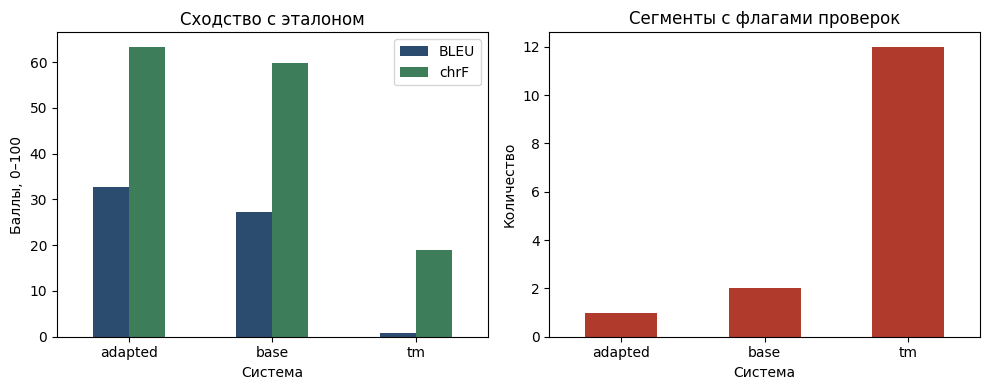

In [13]:
bleu_metric = BLEU(tokenize="13a", lowercase=False, smooth_method="exp", effective_order=False)
chrf_metric = CHRF(char_order=6, word_order=0, beta=2)
sentence_bleu = BLEU(tokenize="13a", lowercase=False, smooth_method="exp", effective_order=True)

def score_table(frame, by_type=False):
    rows = []
    keys = ["system", "type"] if by_type else ["system"]
    for key, part in frame.groupby(keys):
        key = key if isinstance(key, tuple) else (key,)
        hyp, ref = part["prediction"].tolist(), part["ru_ref"].tolist()
        row = dict(zip(keys, key))
        row.update(n=len(part), BLEU=bleu_metric.corpus_score(hyp, [ref]).score,
                   chrF=chrf_metric.corpus_score(hyp, [ref]).score,
                   qa_flagged=int(part["qa_any"].sum()))
        rows.append(row)
    return pd.DataFrame(rows)


summary = score_table(results)
by_type = score_table(results, by_type=True)
metric_signatures = {"BLEU": str(bleu_metric.get_signature()), "chrF": str(chrf_metric.get_signature())}
results["sentence_BLEU"] = [sentence_bleu.sentence_score(h, [r]).score for h, r in zip(results["prediction"], results["ru_ref"])]
results["sentence_chrF"] = [chrf_metric.sentence_score(h, [r]).score for h, r in zip(results["prediction"], results["ru_ref"])]
display(summary.round(2))
display(by_type.round(2))
print("Подписи метрик:", metric_signatures)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
summary.set_index("system")[["BLEU", "chrF"]].plot.bar(ax=axes[0], color=["#2B4C6F", "#3E7D5A"], rot=0)
axes[0].set(title="Сходство с эталоном", ylabel="Баллы, 0–100", xlabel="Система")
summary.set_index("system")["qa_flagged"].plot.bar(ax=axes[1], color="#B03A2B", rot=0)
axes[1].set(title="Сегменты с флагами проверок", ylabel="Количество", xlabel="Система")
plt.tight_layout()
plt.show()

## 11. Языковой разбор и ручная оценка

Сначала просмотрите все переводы с флагами. Затем сравните исходную и адаптированную
модель по каждой строке: где chrF вырос и где упал сильнее всего. Разность chrF помогает
выбрать примеры, но сама по себе не означает, что ошибка исправлена или появилась.

Для каждого выбранного сегмента ответьте на вопросы:

1. Сохранён ли смысл оригинала, включая отрицания и условия?
2. Подходит ли форма для кнопки, заголовка или сообщения?
3. Правильно ли согласованы слова, естественно ли они сочетаются?
4. Соблюдены ли термины и технические требования?

Ошибки отмечайте по учебным категориям MQM из работы № 3: смысл, нормы языка,
терминология, стиль, разметка. Флаги и низкие баллы не заменяют ручную разметку.

**Что делает следующий блок:** показывает строки с наибольшим ростом и падением chrF,
строки с флагами и готовит таблицу для ручной разметки.

In [14]:
paired = results.pivot(index="id", columns="system", values="prediction").reset_index()
paired = test[["id", "type", "en", "ru_ref"]].merge(paired, on="id", validate="one_to_one")
scores = results.pivot(index="id", columns="system", values="sentence_chrF")
paired["delta_chrF"] = paired["id"].map(scores["adapted"] - scores["base"])
display(paired.sort_values("delta_chrF").head(4))
display(paired.sort_values("delta_chrF", ascending=False).head(4))
display(results.loc[results["qa_any"], ["id", "system", "en", "prediction", "qa_flags"]])

# Пустые поля означают «ещё не размечено», а не «ошибок нет».
manual_review = results[["id", "system", "type", "en", "ru_ref", "prediction"]].copy()
for column in ["category", "severity", "comment"]:
    manual_review[column] = ""
print("Подготовлен шаблон ручной разметки:", len(manual_review), "строк.")

,id,type,en,ru_ref,adapted,base,tm,delta_chrF
7,s038,интерфейс,Connection restored,Соединение восстановлено,Повторное подключение,Восстановление связи,Параметр задаёт максимальное число одновременн...,-32.227825
22,s110,маркетинг,Security you do not have to think about.,"Безопасность, о которой не нужно думать.","Безопасность, о которой вы не должны думать.","Безопасность, о которой тебе не нужно думать.","Прежде чем начать, убедитесь, что у вас есть п...",-17.358378
23,s120,маркетинг,"Come for the speed, stay for the quality.","Останьтесь ради качества, придя за скоростью.",Приходите за скоростью и оставайтесь на высоте.,"Приходите за скоростью, оставайтесь на уровне ...",Исполнитель несёт ответственность за качество ...,-10.814982
31,s160,юридический,Costs incurred by each party are borne by that...,"Расходы, понесённые каждой стороной, несёт эта...","Затраты, понесенные каждой стороной, покрывают...","Расходы, понесенные каждой из сторон, покрываю...",Обстоятельства непреодолимой силы освобождают ...,-7.587474


,id,type,en,ru_ref,adapted,base,tm,delta_chrF
15,s074,документация,Temporary files are removed when the session e...,Временные файлы удаляются при завершении сеанса.,Временные файлы удаляются по завершении сеанса.,Временные файлы удаляются после окончания сессии.,"Мы готовы, когда готовы вы.",30.564818
16,s083,маркетинг,Try it free for 30 days. No card required.,Попробуйте бесплатно 30 дней. Карта не нужна.,Попробуйте бесплатно 30 дней. Карточка не треб...,Попробуй бесплатно 30 дней.,"Файлы журналов хранятся 30 дней, после чего уд...",19.498026
25,s130,юридический,Notices are deemed delivered on the day they a...,Уведомления считаются доставленными в день их ...,Уведомления считаются доставляемыми в день их ...,"Уведомления считаются доставляемыми в день, ко...","Файлы журналов хранятся 30 дней, после чего уд...",17.950998
29,s149,юридический,Use of the Service for unlawful purposes is pr...,Использование Сервиса в противоправных целях з...,Использование Сервиса в незаконных целях запре...,Использование этой службы в незаконных целях з...,Настоящие Условия регулируют использование Сер...,15.885232


,id,system,en,prediction,qa_flags
5,s028,adapted,Session will end in {minutes} min,Сеанс заканчивается в {минуты} мин.,[поля/теги]
37,s028,base,Session will end in {minutes} min,Сессия закончится в {минуты} мин.,[поля/теги]
48,s083,base,Try it free for 30 days. No card required.,Попробуй бесплатно 30 дней.,[возможная потеря отрицания]
65,s010,tm,Unable to connect to the server,Параметр задаёт максимальное число одновременн...,[возможная потеря отрицания]
67,s020,tm,Storage almost full,"Файлы журналов хранятся 30 дней, после чего уд...",[числа]
69,s028,tm,Session will end in {minutes} min,"Настройка занимает минуты, а не недели.",[поля/теги]
75,s060,tm,The connection is encrypted with the TLS 1.3 p...,Параметр задаёт максимальное число одновременн...,[числа]
76,s066,tm,Read permissions are granted at the level of a...,Переименовать папку,[короткий перевод]
77,s067,tm,The migration script must be run only once.,Пароль должен содержать не менее 8 символов,[числа]
78,s073,tm,The server responds with code 429 when the req...,Пользователь вправе потребовать удаления своих...,[числа]


Подготовлен шаблон ручной разметки: 96 строк.


## 12. Сохранение результатов

Для отчёта сохраняются параметры, версии библиотек, состав частей, кривые потерь,
переводы, метрики и таблица для ручной разметки. Каждый запуск получает свою папку
в `lab5_outputs/`, поэтому прежние результаты не стираются.

Саму модель по умолчанию не сохраняем: она занимает около 300 МБ. Если она нужна
для продолжения работы, поставьте `EXPORT_MODEL = True`. В режиме `saved` модель
не сохраняется.

**Что делает следующий блок:** записывает результаты в новую папку и печатает её путь.

In [15]:
output_dir = Path("lab5_outputs") / datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
output_dir.mkdir(parents=True, exist_ok=False)
export_manifest = {**run_manifest, "view_mode": MODE, "metric_signatures": metric_signatures}
(output_dir / "manifest.json").write_text(json.dumps(export_manifest, ensure_ascii=False, indent=2), encoding="utf-8")
split_data[["id", "type", "group", "split"]].to_csv(output_dir / "split.csv", index=False, encoding="utf-8")
neural_predictions.to_csv(output_dir / "predictions.csv", index=False, encoding="utf-8")
history.to_csv(output_dir / "history.csv", index=False, encoding="utf-8")
summary.to_csv(output_dir / "summary.csv", index=False, encoding="utf-8")
by_type.to_csv(output_dir / "by_type.csv", index=False, encoding="utf-8")
results.to_csv(output_dir / "all_results.csv", index=False, encoding="utf-8")
paired.to_csv(output_dir / "paired.csv", index=False, encoding="utf-8")
manual_review.to_csv(output_dir / "manual_review.csv", index=False, encoding="utf-8")
if MODE == "train" and EXPORT_MODEL:
    model.save_pretrained(output_dir / "model", safe_serialization=True)
    tokenizer.save_pretrained(output_dir / "model")
print("Результаты:", output_dir)

Результаты: lab5_outputs\20261115T192119_383653Z


## Самостоятельная часть

1. **Сформулируйте гипотезу до запуска.** Какие ошибки может исправить адаптация:
   терминологию, форму команд, согласование? Какие ошибки она исправить не сможет?
2. **Проверьте разбиение.** Разберите найденные группы похожих оригиналов и объясните,
   почему их нельзя распределять по разным частям. Если групп нет, проверьте способ
   на двух придуманных парах, где отличается только число или имя поля; в тест их
   не добавляйте. Обсудите, что этот способ мог пропустить.
3. **Разберите обучение.** По двум кривым объясните выбор эпохи. Падает ли проверочная
   потеря вместе с обучающей? Что означал бы выбор эпохи 0? Если лучшей оказалась
   последняя эпоха, что это говорит о выбранном числе эпох?
4. **Сравните три системы.** Приведите общую таблицу и результаты по типам контента.
   Не называйте память переводов «плохим переводчиком»: объясните, что она возвращает
   и когда полезна.
5. **Разметьте не менее восьми тестовых сегментов для всех трёх систем.** Включите
   случаи роста и падения метрики, строки с полями или числами и хотя бы одно
   перефразирование. Отмечайте исправленные, оставшиеся и новые ошибки. Если ошибки
   нет, так и запишите: «нет ошибки».
6. **Измените один фактор**, например скорость обучения или объём обучающих данных.
   Части `validation` и `test` оставьте прежними. Чтобы уменьшить обучающие данные,
   возьмите часть исходного `train`, а не делайте новое разбиение. Настройку выбирайте
   по `validation`, а не по тестовым баллам: тест, на который вы уже смотрели при выборе
   настроек, перестаёт быть независимым.
7. **Проверьте правило отрицания.** Найдите ложные тревоги и пропуски. Предложите
   улучшение и покажите, на каких строках оно помогло и чего всё ещё не проверяет.

### Дополнительно: связь с классификацией из работы № 1

Обучите классификатор типа контента только на `train.ru_ref`. Сначала проверьте его
качество на эталонах теста: слабый классификатор не может надёжно судить о регистре.
Затем примените его к переводам систем и разберите случаи, когда после адаптации
предсказанный тип изменился. Метка классификатора не говорит о правильности перевода.

### Отчёт

* Гипотеза, параметры запуска, размеры частей и обоснование группировки.
* Две кривые потерь и объяснение выбранной эпохи.
* Сравнение памяти переводов, исходной и адаптированной модели; подписи метрик и разбор по типам.
* Ручная разметка, примеры исправленных и новых ошибок, ограничения проверок.
* Вывод: что именно изменилось и каких данных не хватает для уверенного вывода.

Рост BLEU не обязателен для успешной работы. Если результат не изменился или ухудшился,
разберите его так же внимательно, как улучшение.

## Источники

* [Карточка модели Helsinki-NLP/opus-mt-en-ru](https://huggingface.co/Helsinki-NLP/opus-mt-en-ru).
* [Transformers: обучение модели перевода](https://huggingface.co/docs/transformers/v4.57.1/en/tasks/translation).
* [DataCollatorForSeq2Seq: дополнение пакетов и маска меток](https://huggingface.co/docs/transformers/v4.57.1/en/main_classes/data_collator#transformers.DataCollatorForSeq2Seq).
* [SacreBLEU: реализация и подписи метрик](https://github.com/mjpost/sacrebleu).
* Происхождение учебных данных: `data/О_данных.md`.